# Zomato - Part 4 : Rating Prediction Models (Machine Learning)

### Why do we need a rating prediction model for a *recommendation* system ?

From Part 3 : **~24% restaurants are unrated** (NEW restaurants, `votes = 0`).

If our recommender only uses ratings, these restaurants will **never** be recommended -> this is the famous
**Cold Start Problem** :( A new restaurant can't get ratings without being recommended, and can't be recommended without ratings !

-------------------------------------------------------

### Solution :
Train a ML model that learns : *"what kind of restaurant gets what kind of rating"* using only things we know
even for a brand new restaurant :
- cuisines, restaurant type, meal types
- cost, price level
- location info
- online order / table booking
- chain info

Then use it to **predict the rating of unrated restaurants**, so they can also enter the recommender (with less confidence).

-------------------------------------------------------

### Plan :
1. Load `restaurants_processed.csv` & build the feature matrix
2. Train / Test split
3. Baseline model (always predict the mean) -> anything we build must beat this !
4. Linear models : Linear Regression, Ridge
5. Tree models : Decision Tree, Random Forest, Gradient Boosting
6. Compare with Cross Validation
7. Hyperparameter tuning of the best model
8. Error analysis & Feature importance
9. Predict ratings for the unrated restaurants & save

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_style('whitegrid')
sns.set_palette("husl")

plt.rcParams['figure.figsize'] = (12,6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
%matplotlib inline

In [4]:
from sklearn.model_selection import train_test_split, cross_validate, KFold, RandomizedSearchCV
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

In [5]:
rest = pd.read_csv("restaurants_processed.csv")
print("Shape: ", rest.shape)
rest.head(3)

Shape:  (12463, 27)


,rest_id,name,address,location,city,rest_type,cuisines,meal_types,cost_for_two,rate,...,price_category,price_level,num_cuisines,num_meal_types,num_listings,chain_size,is_chain,loc_rest_count,loc_avg_cost,tags
0,0,#Feeltheroll,"Opposite Mantri Commercio, Outer Ring Road, De...",Bellandur,Bellandur,Quick Bites,Fast Food,Delivery,200.0,3.4,...,Budget,0,1,1,2,1,0,362,482.5,fast_food rt_quick_bites meal_delivery price_b...
1,1,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Hsr,Btm,Quick Bites,"Fast Food, Beverages","Delivery, Dine-Out",400.0,3.9,...,Affordable,1,2,2,9,1,0,704,440.6,fast_food beverages rt_quick_bites meal_delive...
2,2,#Refuel,"7, Ground Floor, RR Commercial Complex, Akshay...",Bannerghatta Road,Bannerghatta Road,Cafe,"Cafe, Beverages","Cafes, Delivery, Dine-Out",400.0,3.7,...,Affordable,1,2,3,3,1,0,474,422.0,cafe beverages rt_cafe meal_cafes meal_deliver...


## 1. Building the Feature Matrix `X`

### Features we will use :

| Type | Columns |
|---|---|
| Binary | `online_order`, `book_table`, `is_chain` |
| Numerical | `log_cost`, `price_level`, `num_cuisines`, `num_meal_types`, `chain_size`, `loc_rest_count`, `loc_avg_cost` |
| Multi-hot | cuisines (min 20 restaurants), rest type, meal types |
| One-hot | location |

### Features we will NOT use (and why) :
- `votes`, `log_votes`, `weighted_rating` : a NEW restaurant has 0 votes, so the model can't use this info at prediction time.
  (Using it would make test scores look great but the model would be useless for our actual goal.)
- `num_listings` : depends on how many sections zomato listed the restaurant in, which partly depends on popularity. Removing it to be safe.
- `name`, `address` : identifiers, not features.

In [6]:
def to_list(s):
    return [x.strip() for x in str(s).split(",") if x.strip() != ""]


def multi_hot(series, prefix, min_count=1):
    mlb = MultiLabelBinarizer()
    arr = mlb.fit_transform(series.apply(to_list))
    out = pd.DataFrame(arr, columns=[prefix + c for c in mlb.classes_], index=series.index)
    keep = out.columns[out.sum() >= min_count]   # drop very rare categories
    return out[keep]


cuisine_X = multi_hot(rest["cuisines"], "cuisine_", min_count=20)
rtype_X = multi_hot(rest["rest_type"], "rtype_", min_count=20)
meal_X = multi_hot(rest["meal_types"], "meal_")

# location : one-hot, but rare locations (<20 restaurants) grouped into "Other"
loc_counts = rest["location"].value_counts()
loc_clean = rest["location"].where(rest["location"].map(loc_counts) >= 20, "Other")
loc_X = pd.get_dummies(loc_clean, prefix="loc").astype(int)

print("Cuisine cols  : ", cuisine_X.shape[1])
print("Rest type cols: ", rtype_X.shape[1])
print("Meal type cols: ", meal_X.shape[1])
print("Location cols : ", loc_X.shape[1])

Cuisine cols  :  55
Rest type cols:  19
Meal type cols:  7
Location cols :  72


In [7]:
base_cols = [
    "online_order", "book_table", "is_chain",
    "log_cost", "price_level", "num_cuisines", "num_meal_types",
    "chain_size", "loc_rest_count", "loc_avg_cost",
]

X_all = pd.concat([rest[base_cols], cuisine_X, rtype_X, meal_X, loc_X], axis=1)

print("Total features: ", X_all.shape[1])

Total features:  163


### Splitting into rated (for training) and unrated (for prediction later)

In [8]:
rated_mask = rest["is_rated"] == 1

X = X_all[rated_mask]
y = rest.loc[rated_mask, "rate"]

X_unrated = X_all[~rated_mask]

print("Rated (train + test) : ", X.shape)
print("Unrated (to predict) : ", X_unrated.shape)

Rated (train + test) :  (9459, 163)
Unrated (to predict) :  (3004, 163)


## 2. Train / Test Split

80% train , 20% test. `random_state=42` so results are reproducible.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train: ", X_train.shape, " Test: ", X_test.shape)
print(f"y_train mean = {y_train.mean():.3f} , y_test mean = {y_test.mean():.3f}")

Train:  (7567, 163)  Test:  (1892, 163)
y_train mean = 3.624 , y_test mean = 3.626


### Evaluation Metrics

- **RMSE** (Root Mean Squared Error) : avg error in "rating points", punishes big errors more.
- **MAE** (Mean Absolute Error) : avg absolute error, easy to understand. MAE = 0.2 means *"on avg we are off by 0.2 stars"*.
- **R²** : how much of the variance in rating is explained by the model. `0` = as good as predicting mean, `1` = perfect.

In [10]:
results = []


def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    row = {
        "model" : name,
        "RMSE" : np.sqrt(mean_squared_error(y_te, pred)),
        "MAE" : mean_absolute_error(y_te, pred),
        "R2" : r2_score(y_te, pred),
    }
    results.append(row)
    print(f"{name:25s} | RMSE = {row['RMSE']:.4f} | MAE = {row['MAE']:.4f} | R2 = {row['R2']:.4f}")
    return model

## 3. Baseline Model

Simplest possible "model" : predict the **mean rating** for every restaurant.

In [11]:
baseline = evaluate("Baseline (mean)", DummyRegressor(strategy="mean"))

Baseline (mean)           | RMSE = 0.4296 | MAE = 0.3461 | R2 = -0.0000


So with zero intelligence we are off by ~0.35 stars on average. Lets see if ML can do better ;)

## 4. Linear Models

Linear models are sensitive to feature scale, so `StandardScaler` is added in a pipeline.

**Ridge** = Linear Regression + L2 regularization (penalizes large coefficients -> helps when we have many correlated one-hot columns).

In [12]:
lin_reg = evaluate("Linear Regression", make_pipeline(StandardScaler(), LinearRegression()))
ridge = evaluate("Ridge (alpha=10)", make_pipeline(StandardScaler(), Ridge(alpha=10)))

Linear Regression         | RMSE = 0.3601 | MAE = 0.2843 | R2 = 0.2975


Ridge (alpha=10)          | RMSE = 0.3600 | MAE = 0.2843 | R2 = 0.2976


## 5. Tree Based Models

Trees don't need scaling, and they can catch **non-linear** relations & **interactions**
(eg : "*costly + table booking + Koramangala*" together -> very high rating).

In [13]:
tree = evaluate("Decision Tree (depth=8)", DecisionTreeRegressor(max_depth=8, random_state=42))

Decision Tree (depth=8)   | RMSE = 0.3795 | MAE = 0.2997 | R2 = 0.2194


In [14]:
rf = evaluate("Random Forest", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42))

Random Forest             | RMSE = 0.3511 | MAE = 0.2743 | R2 = 0.3320


In [15]:
hgb = evaluate("Hist Gradient Boosting", HistGradientBoostingRegressor(random_state=42))

Hist Gradient Boosting    | RMSE = 0.3418 | MAE = 0.2692 | R2 = 0.3670


### Comparing all models on the test set

In [16]:
results_df = pd.DataFrame(results).set_index("model").round(4)
results_df

,RMSE,MAE,R2
model,,,
Baseline (mean),0.4296,0.3461,-0.0000
Linear Regression,0.3601,0.2843,0.2975
Ridge (alpha=10),0.3600,0.2843,0.2976
Decision Tree (depth=8),0.3795,0.2997,0.2194
Random Forest,0.3511,0.2743,0.3320
Hist Gradient Boosting,0.3418,0.2692,0.3670


-------------------------------------------------------
### Observations :

- **Every** model beats the baseline (RMSE 0.43) -> our features do carry information about rating.
- Linear Regression & Ridge give almost the same result (R² ~0.30). With ~7.5k rows and 163 features, overfitting is not a big issue for linear models.
- A single **Decision Tree** is the worst ML model (R² ~0.22) -> one tree is too unstable.
- **Random Forest** (many trees averaged) fixes that -> R² ~0.33.
- **Hist Gradient Boosting** is the best (R² ~0.37, MAE ~0.27).

-------------------------------------------------------

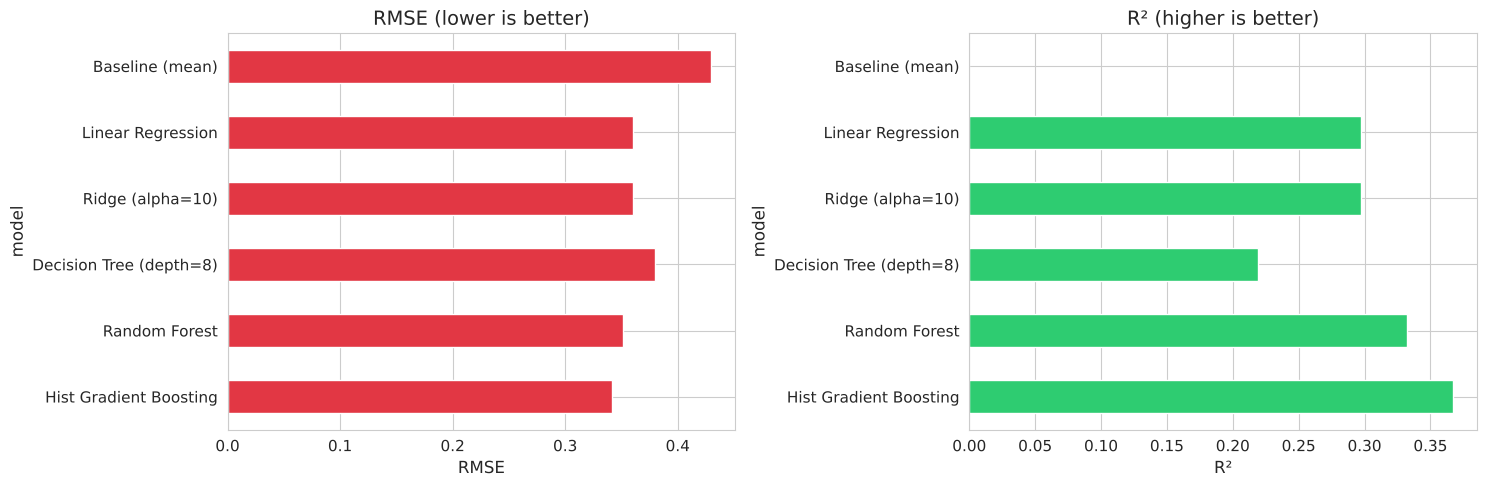

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

results_df["RMSE"].plot.barh(ax=axes[0], color="#E23744")
axes[0].set_title("RMSE (lower is better)")
axes[0].set_xlabel("RMSE")
axes[0].invert_yaxis()

results_df["R2"].plot.barh(ax=axes[1], color="#2ECC71")
axes[1].set_title("R² (higher is better)")
axes[1].set_xlabel("R²")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("plots/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Cross Validation

One train/test split can be lucky or unlucky. **5-Fold Cross Validation** trains & tests 5 times on different splits
and gives us mean ± std -> more reliable comparison.

(Doing CV only for the main candidates to save time.)

In [18]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Ridge" : make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest" : RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "Hist Gradient Boosting" : HistGradientBoostingRegressor(random_state=42),
}

cv_rows = []
for name, model in cv_models.items():
    cv = cross_validate(model, X, y, cv=kf, scoring=["neg_root_mean_squared_error", "r2"])
    rmse = -cv["test_neg_root_mean_squared_error"]
    r2 = cv["test_r2"]
    cv_rows.append({"model": name, "RMSE mean": rmse.mean(), "RMSE std": rmse.std(), "R2 mean": r2.mean(), "R2 std": r2.std()})

pd.DataFrame(cv_rows).set_index("model").round(4)

,RMSE mean,RMSE std,R2 mean,R2 std
model,,,,
Ridge,0.3674,0.0072,0.2680,0.0178
Random Forest,0.3514,0.0057,0.3301,0.0142
Hist Gradient Boosting,0.3472,0.0073,0.3462,0.0210


## 7. Hyperparameter Tuning

Gradient Boosting is our best candidate. Lets tune it using `RandomizedSearchCV`
(tries random combinations instead of ALL combinations like GridSearch -> much faster).

Parameters :
- `learning_rate` : how big each boosting step is
- `max_iter` : number of trees
- `max_leaf_nodes` : complexity of each tree
- `min_samples_leaf` : min samples in a leaf (bigger = less overfitting)
- `l2_regularization` : penalty on leaf values

In [19]:
param_dist = {
    "learning_rate" : [0.03, 0.05, 0.1],
    "max_iter" : [200, 400, 600],
    "max_leaf_nodes" : [15, 31, 63],
    "min_samples_leaf" : [10, 20, 40],
    "l2_regularization" : [0.0, 0.5, 1.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)

print("Best params : ", search.best_params_)
print(f"Best CV RMSE: {-search.best_score_:.4f}")

Best params :  {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.0}
Best CV RMSE: 0.3505


In [20]:
best_model = evaluate("HGB (tuned)", search.best_estimator_)

HGB (tuned)               | RMSE = 0.3412 | MAE = 0.2685 | R2 = 0.3692


CV results confirm the ranking : **HGB > Random Forest > Ridge**, and the std across folds is small (~0.007) so the ranking is stable.

Tuning gave only a small improvement (default params were already good), which is quite normal for gradient boosting.

## 8. Error Analysis

### 8.1 Actual vs Predicted

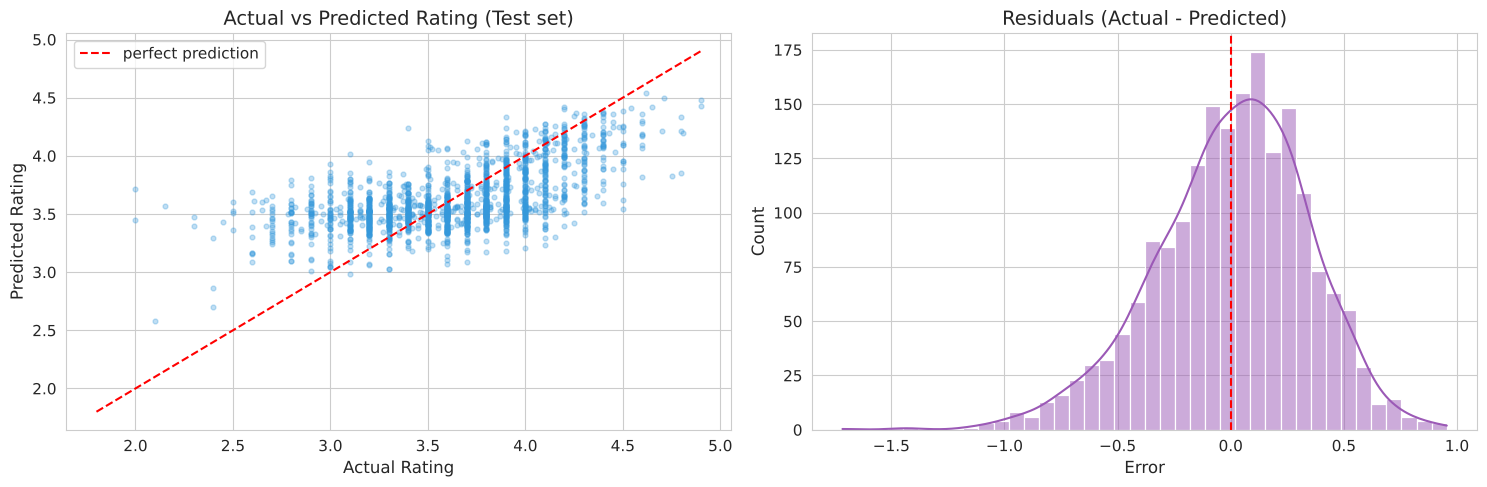

In [21]:
y_pred = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=12, color="#3498DB")
axes[0].plot([1.8, 4.9], [1.8, 4.9], "r--", label="perfect prediction")
axes[0].set_title("Actual vs Predicted Rating (Test set)")
axes[0].set_xlabel("Actual Rating")
axes[0].set_ylabel("Predicted Rating")
axes[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, bins=40, kde=True, color="#9B59B6", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residuals (Actual - Predicted)")
axes[1].set_xlabel("Error")

plt.tight_layout()
plt.savefig("plots/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 Where does the model make mistakes ?

In [22]:
err_df = pd.DataFrame({"actual": y_test, "pred": y_pred})
err_df["abs_err"] = (err_df["actual"] - err_df["pred"]).abs()
err_df["rating_bucket"] = pd.cut(err_df["actual"], bins=[0, 3, 3.5, 4, 4.5, 5],
                                 labels=["<3", "3-3.5", "3.5-4", "4-4.5", "4.5+"])

err_df.groupby("rating_bucket", observed=True)["abs_err"].agg(["mean", "count"]).round(3)

,mean,count
rating_bucket,,
<3,0.622,159
3-3.5,0.222,617
3.5-4,0.215,805
4-4.5,0.310,290
4.5+,0.453,21


-------------------------------------------------------
### Observations :

- The model is good in the middle (3 - 4.0) where most of the data is -> avg error only ~0.22.
- It struggles at the **extremes** : avg error ~0.62 for `<3` rated and ~0.45 for `4.5+` rated restaurants -> it predicts them closer to the middle.
  This is called **regression to the mean**, very common when features don't fully explain the target.
- Makes sense : two "Quick Bites, North Indian, Rs.300, BTM" places look *identical* to the model, but one can be
  amazing and other one terrible. Food taste / service / hygiene is simply not in our data !

-------------------------------------------------------

### 8.3 Feature Importance

Using **Permutation Importance** : shuffle one feature at a time and see how much the score drops.
Bigger drop = more important feature. (more reliable than the default tree importance)

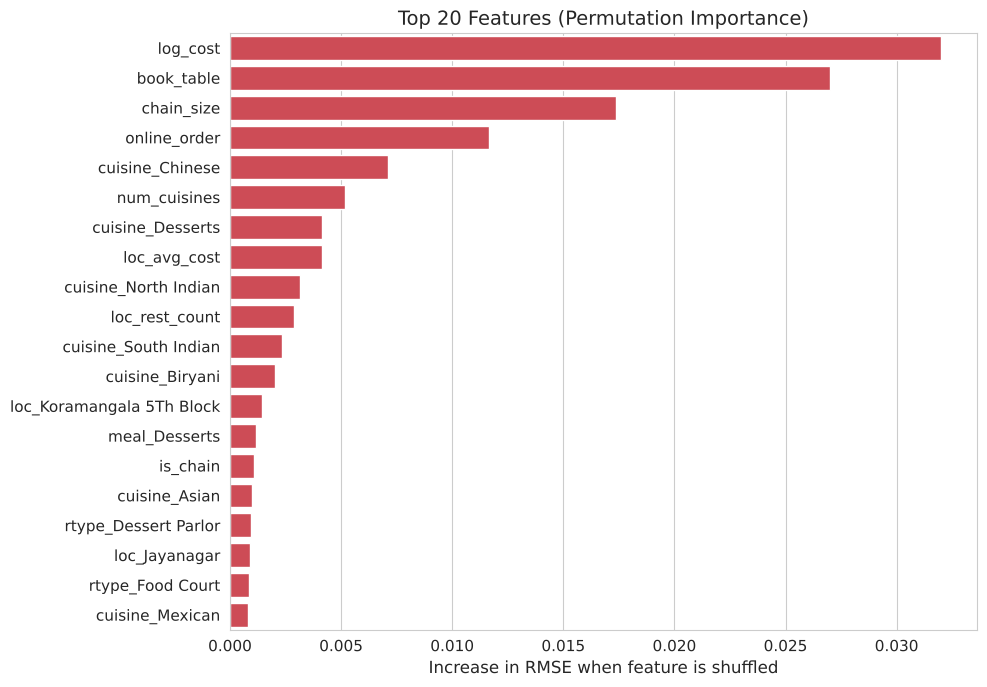

In [23]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1,
                              scoring="neg_root_mean_squared_error")

importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(10,7))
sns.barplot(x=importance.head(20).values, y=importance.head(20).index, color="#E23744")
plt.title("Top 20 Features (Permutation Importance)")
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.ylabel("")
plt.tight_layout()
plt.savefig("plots/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

-------------------------------------------------------
### Observations :

- `log_cost` and `book_table` are the top 2 features -> exactly what we saw in the EDA heatmap ;)
- `chain_size` is 3rd : being part of a bigger brand tells a lot about the rating.
- `online_order` matters more here than in EDA (alone it had only 0.08 correlation) -> the model uses it in **combination** with other features.
- Cuisines like `Chinese`, `Desserts`, `North Indian`, `South Indian`, `Biryani` are important : these were the lower rated cuisines in Part 2.
- Location features (`loc_avg_cost`, `loc_rest_count`, `Koramangala 5Th Block`) also show up.

-------------------------------------------------------

### 8.4 Experiment : What if we *did* use votes ?

Just to see how much information is in `votes` (which we don't have for new restaurants).

In [24]:
X_votes = X.copy()
X_votes["log_votes"] = rest.loc[rated_mask, "log_votes"]

Xv_train, Xv_test, yv_train, yv_test = train_test_split(X_votes, y, test_size=0.2, random_state=42)

_ = evaluate("HGB + votes (NOT usable)", HistGradientBoostingRegressor(**search.best_params_, random_state=42),
             Xv_train, yv_train, Xv_test, yv_test)

HGB + votes (NOT usable)  | RMSE = 0.2953 | MAE = 0.2129 | R2 = 0.5276


Big jump in R² (~0.37 -> ~0.53) ! This confirms what EDA said : **popularity (votes) is the strongest signal of rating**.

But again, we can't use it for NEW restaurants -> so our final model stays **without** votes.
In the recommender, for the rated restaurants we will directly use their real (weighted) rating anyway.

## 9. Predicting the Ratings for Unrated Restaurants

Final model = tuned HGB, **re-trained on ALL rated data** (train + test), because more data = better model.

In [25]:
final_model = HistGradientBoostingRegressor(**search.best_params_, random_state=42)
final_model.fit(X, y)

rest["predicted_rate"] = np.nan
rest.loc[~rated_mask, "predicted_rate"] = final_model.predict(X_unrated).round(2)

rest.loc[~rated_mask, ["name", "location", "rest_type", "cuisines", "cost_for_two", "predicted_rate"]].head(10)

,name,location,rest_type,cuisines,cost_for_two,predicted_rate
3,#Vibes Restro,Electronic City,Casual Dining,"Continental, Chinese, Italian",700.0,3.22
4,'Brahmins' Thatte Idli,Basaveshwara Nagar,Quick Bites,South Indian,100.0,3.59
5,1 Fahreheit,New Bel Road,Dessert Parlor,"Desserts, Ice Cream",200.0,3.61
30,21 Corner Haus Cafe,Shanti Nagar,Quick Bites,"North Indian, Chinese, Biryani",300.0,3.29
31,22S,Marathahalli,Delivery,"North Indian, Mughlai, Biryani",500.0,3.41
33,24 Hours Cake Delivery,Electronic City,Delivery,Bakery,700.0,3.36
48,38 Sugar Lane,Bellandur,"Takeaway, Delivery","Bakery, Desserts",850.0,3.60
52,3Ice Cubes,Jp Nagar,Beverage Shop,"Juices, Sandwich, Street Food",150.0,3.42
57,4-States,Bellandur,Food Court,South Indian,250.0,3.38
58,46 Ounces Brewgarden,Electronic City,Microbrewery,"Bar Food, Finger Food, Pizza",1600.0,4.17


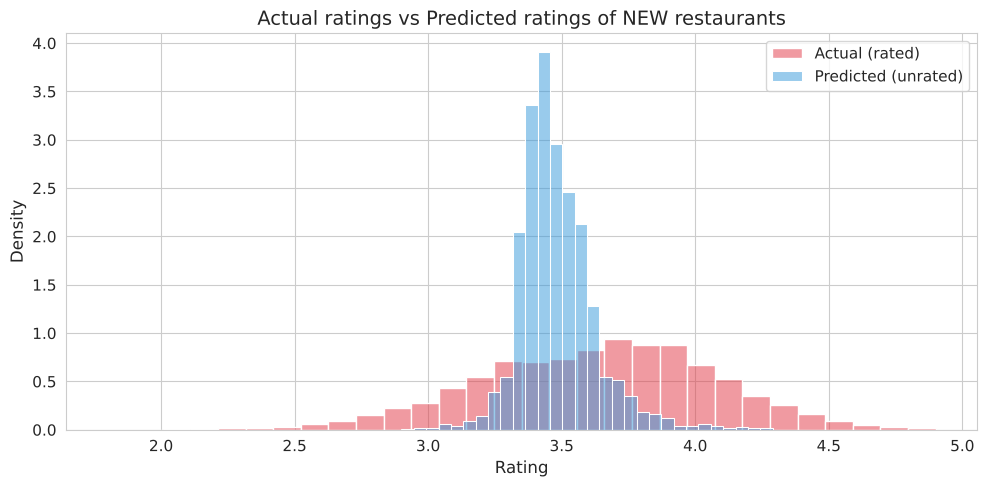

Predicted ratings -> mean = 3.480 , std = 0.143


In [26]:
fig, ax = plt.subplots(figsize=(10,5))

sns.histplot(rest.loc[rated_mask, "rate"], bins=30, stat="density", color="#E23744", alpha=0.5, label="Actual (rated)", ax=ax)
sns.histplot(rest.loc[~rated_mask, "predicted_rate"], bins=30, stat="density", color="#3498DB", alpha=0.5, label="Predicted (unrated)", ax=ax)

ax.set_title("Actual ratings vs Predicted ratings of NEW restaurants")
ax.set_xlabel("Rating")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Predicted ratings -> mean = {rest['predicted_rate'].mean():.3f} , std = {rest['predicted_rate'].std():.3f}")

Two things to notice :
- Predicted mean (~3.48) is **lower** than the mean of rated restaurants (~3.62). NEW restaurants are mostly small quick-bites /
  delivery places with no table booking & low cost, and the model learned that such places usually get lower ratings.
- Predicted ratings are more **concentrated** around the mean (lower std) - expected, because the model is "careful"
(regression to the mean again). This is actually good for us : we don't want to blindly push a NEW restaurant
to the top of recommendations, but we also don't want to hide it forever.

-------------------------------------------------------

### Final score for the recommender : `quality_score`

- **Rated restaurant** -> `weighted_rating` (real ratings, adjusted by votes)
- **Unrated restaurant** -> `predicted_rate`, but pulled a little towards the mean (because it's only a prediction)

$$ quality\_score_{new} = 0.5 \cdot predicted + 0.5 \cdot C $$

In [27]:
C_mean = rest.loc[rated_mask, "rate"].mean()

rest["quality_score"] = rest["weighted_rating"]
rest.loc[~rated_mask, "quality_score"] = 0.5 * rest.loc[~rated_mask, "predicted_rate"] + 0.5 * C_mean
rest["quality_score"] = rest["quality_score"].round(3)

print("Nulls in quality_score: ", rest["quality_score"].isnull().sum())
rest[["name", "is_rated", "rate", "votes", "weighted_rating", "predicted_rate", "quality_score"]].sample(8, random_state=7)

Nulls in quality_score:  0


,name,is_rated,rate,votes,weighted_rating,predicted_rate,quality_score
10392,Sri Venkateshwara Cake House,0,NaN,0,NaN,3.68,3.652
5297,Ishta Upahar,1,3.46,44,3.550,NaN,3.550
3185,Delicacy,1,3.90,311,3.860,NaN,3.860
6023,Kim Lee Restaurant,1,3.80,264,3.771,NaN,3.771
10623,Suryawanshi,1,3.76,18,3.659,NaN,3.659
858,Authentic Aandhra,0,NaN,0,NaN,3.55,3.587
2794,Comboeats,0,NaN,0,NaN,3.50,3.562
1109,Baskin Robbins,0,NaN,0,NaN,3.66,3.642


In [28]:
rest.to_csv("restaurants_final.csv", index=False)
print("Saved -> restaurants_final.csv  ", rest.shape)

Saved -> restaurants_final.csv   (12463, 29)


------------------------------------------------------------------------------

# Summary

| Model | Test RMSE | Test R² | Notes |
|---|---|---|---|
| Baseline (mean) | 0.430 | 0.00 | the bar to beat |
| Linear / Ridge | 0.360 | 0.30 | decent, but can't capture interactions |
| Decision Tree | 0.380 | 0.22 | simple, unstable |
| Random Forest | 0.351 | 0.33 | strong |
| **Hist Gradient Boosting (tuned)** | **0.341** | **0.37** | **best**, chosen as final model |

### Key takeaways :
- Using only "*what the restaurant is*" (cuisine, type, cost, location ...) we can explain a decent part of the rating variance, clearly better than the baseline.
- Cost, `book_table` and chain size are the most important features - same as EDA told us ;)
- The rest of the rating depends on things not in data (taste, service ...) and on popularity (`votes`).
- Now every restaurant (rated or NEW) has a `quality_score` -> **Cold start problem handled** (partly) !

### Possible improvements :
- Text features from `reviews_list` / `dish_liked` (we removed them in Part 1, NLP could add a lot)
- Target encoding of `name` (chain average rating) using out-of-fold encoding
- Try XGBoost / LightGBM / CatBoost

-------------------------------------------------------------
### Next notebook -> `05_Recommendation_System.ipynb`